#### Fashoin MNIST
: 옷과 신발 및 가방의 이미지를 10개의 클래스로 분류
- train set: 6만
- test set: 만
- img: 28*28(흑백)
- class: T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot

In [1]:
from multi_func import *
import torch
from torch import nn, optim
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
import os
os.makedirs('results', exist_ok=True)
D='cuda' if torch.cuda.is_available() else 'cpu'
print(D)

cpu


In [2]:
bs = 32
LR = 1e-3
epoch = 5
cri = nn.CrossEntropyLoss()
nmt = True
mty = "CNN"
dset = "FashionMNIST"
smp = f"results/{mty}_{dset}.pt"

In [3]:
trans = transforms.ToTensor()
trds = datasets.FashionMNIST(root="data", train=True, download=True, transform=trans)
teds = datasets.FashionMNIST(root="data", train=False, download=True, transform=trans)
trdl = DataLoader(trds, batch_size=bs, shuffle=True)
tedl = DataLoader(teds, batch_size=bs, shuffle=True)

100.0%
100.0%
100.0%
100.0%


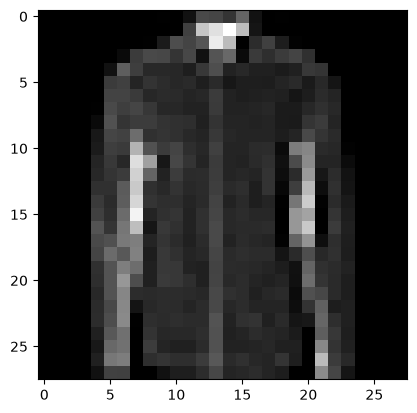

In [4]:
xb, yb = next(iter(trdl))
plt.imshow(xb[0, 0], cmap="gray")

In [5]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.c1 = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1), nn.BatchNorm2d(8), nn.ReLU()
        )
        self.mp = nn.MaxPool2d(2)
        self.c2 = nn.Sequential(
            nn.Conv2d(8, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU()
        )
        self.c3 = nn.Sequential(
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU()
        )
        self.fc = nn.Linear(32 * 3 * 3, 10)

    def forward(self, x):
        x = self.c1(x)
        x = self.mp(x)
        x = self.c2(x)
        x = self.mp(x)
        x = self.c3(x)
        x = self.mp(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x


class cdeep(nn.Module):
    def __init__(self):
        super().__init__()
        self.cb1 = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
        )
        self.mp = nn.MaxPool2d(2)
        self.cb2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
        )
        self.cb3 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
        )
        self.fc = nn.Sequential(
            nn.Linear(128 * 3 * 3, 512), nn.ReLU(), nn.Linear(512, 10)
        )

    def forward(self, x):
        x = self.cb1(x)
        x = self.mp(x)
        x = self.cb2(x)
        x = self.mp(x)
        x = self.cb3(x)
        x = self.mp(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x

In [6]:
m=globals()[mty]().to(D)
xb, _ =next(iter(trdl))
m.eval()
with torch.no_grad():
    print(m(xb.to(D)).shape)

torch.Size([32, 10])


epoch: 1, train loss: 0.434
epoch: 2, train loss: 0.301
epoch: 3, train loss: 0.270
epoch: 4, train loss: 0.254
epoch: 5, train loss: 0.238


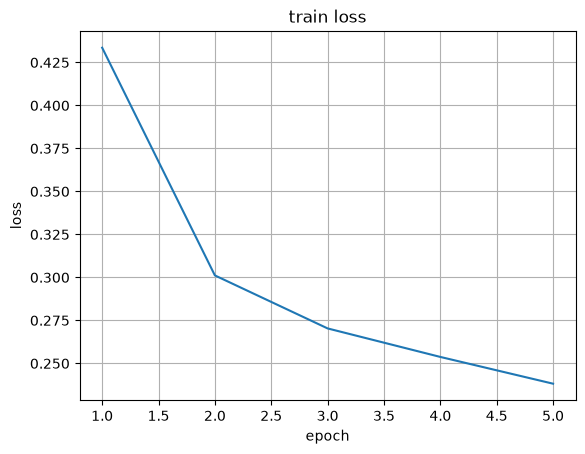

In [7]:
if nmt:
    op = optim.Adam(m.parameters(), lr=LR)
    lh = Train(m, trdl, cri, op, epoch)
    torch.save(m,smp)
    plt.figure()
    plt.plot(range(1, epoch + 1), lh)
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.title("train loss")
    plt.grid()

In [ ]:
lm=torch.load(smp,map_location=D,weights_only=False)

In [ ]:
Test(lm,tedl)

In [ ]:
Test_plot(lm,tedl)

In [ ]:
conf = get_conf(lm, tedl)
plot_conf_mat(conf, teds.classes)
plt.xticks(rotation=45)

torch.Size([32, 32, 28, 28])
torch.Size([32, 64, 14, 14])
torch.Size([32, 128, 7, 7])


Text(0.5, 1.0, '9 - nine (9 - nine)')

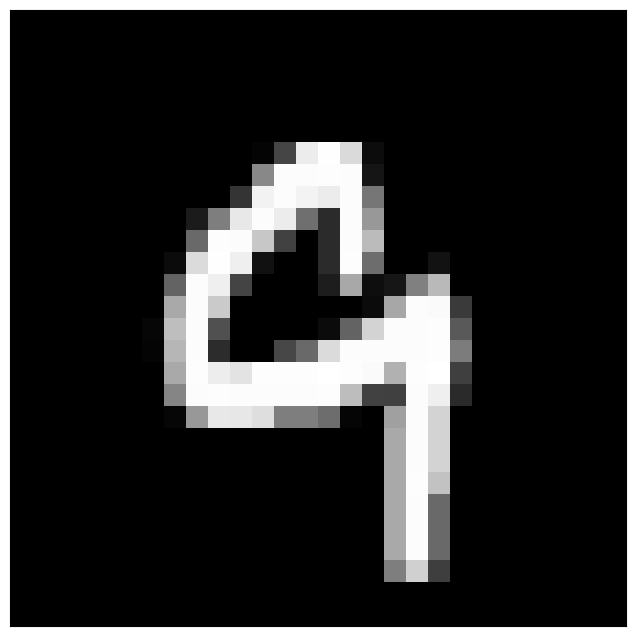

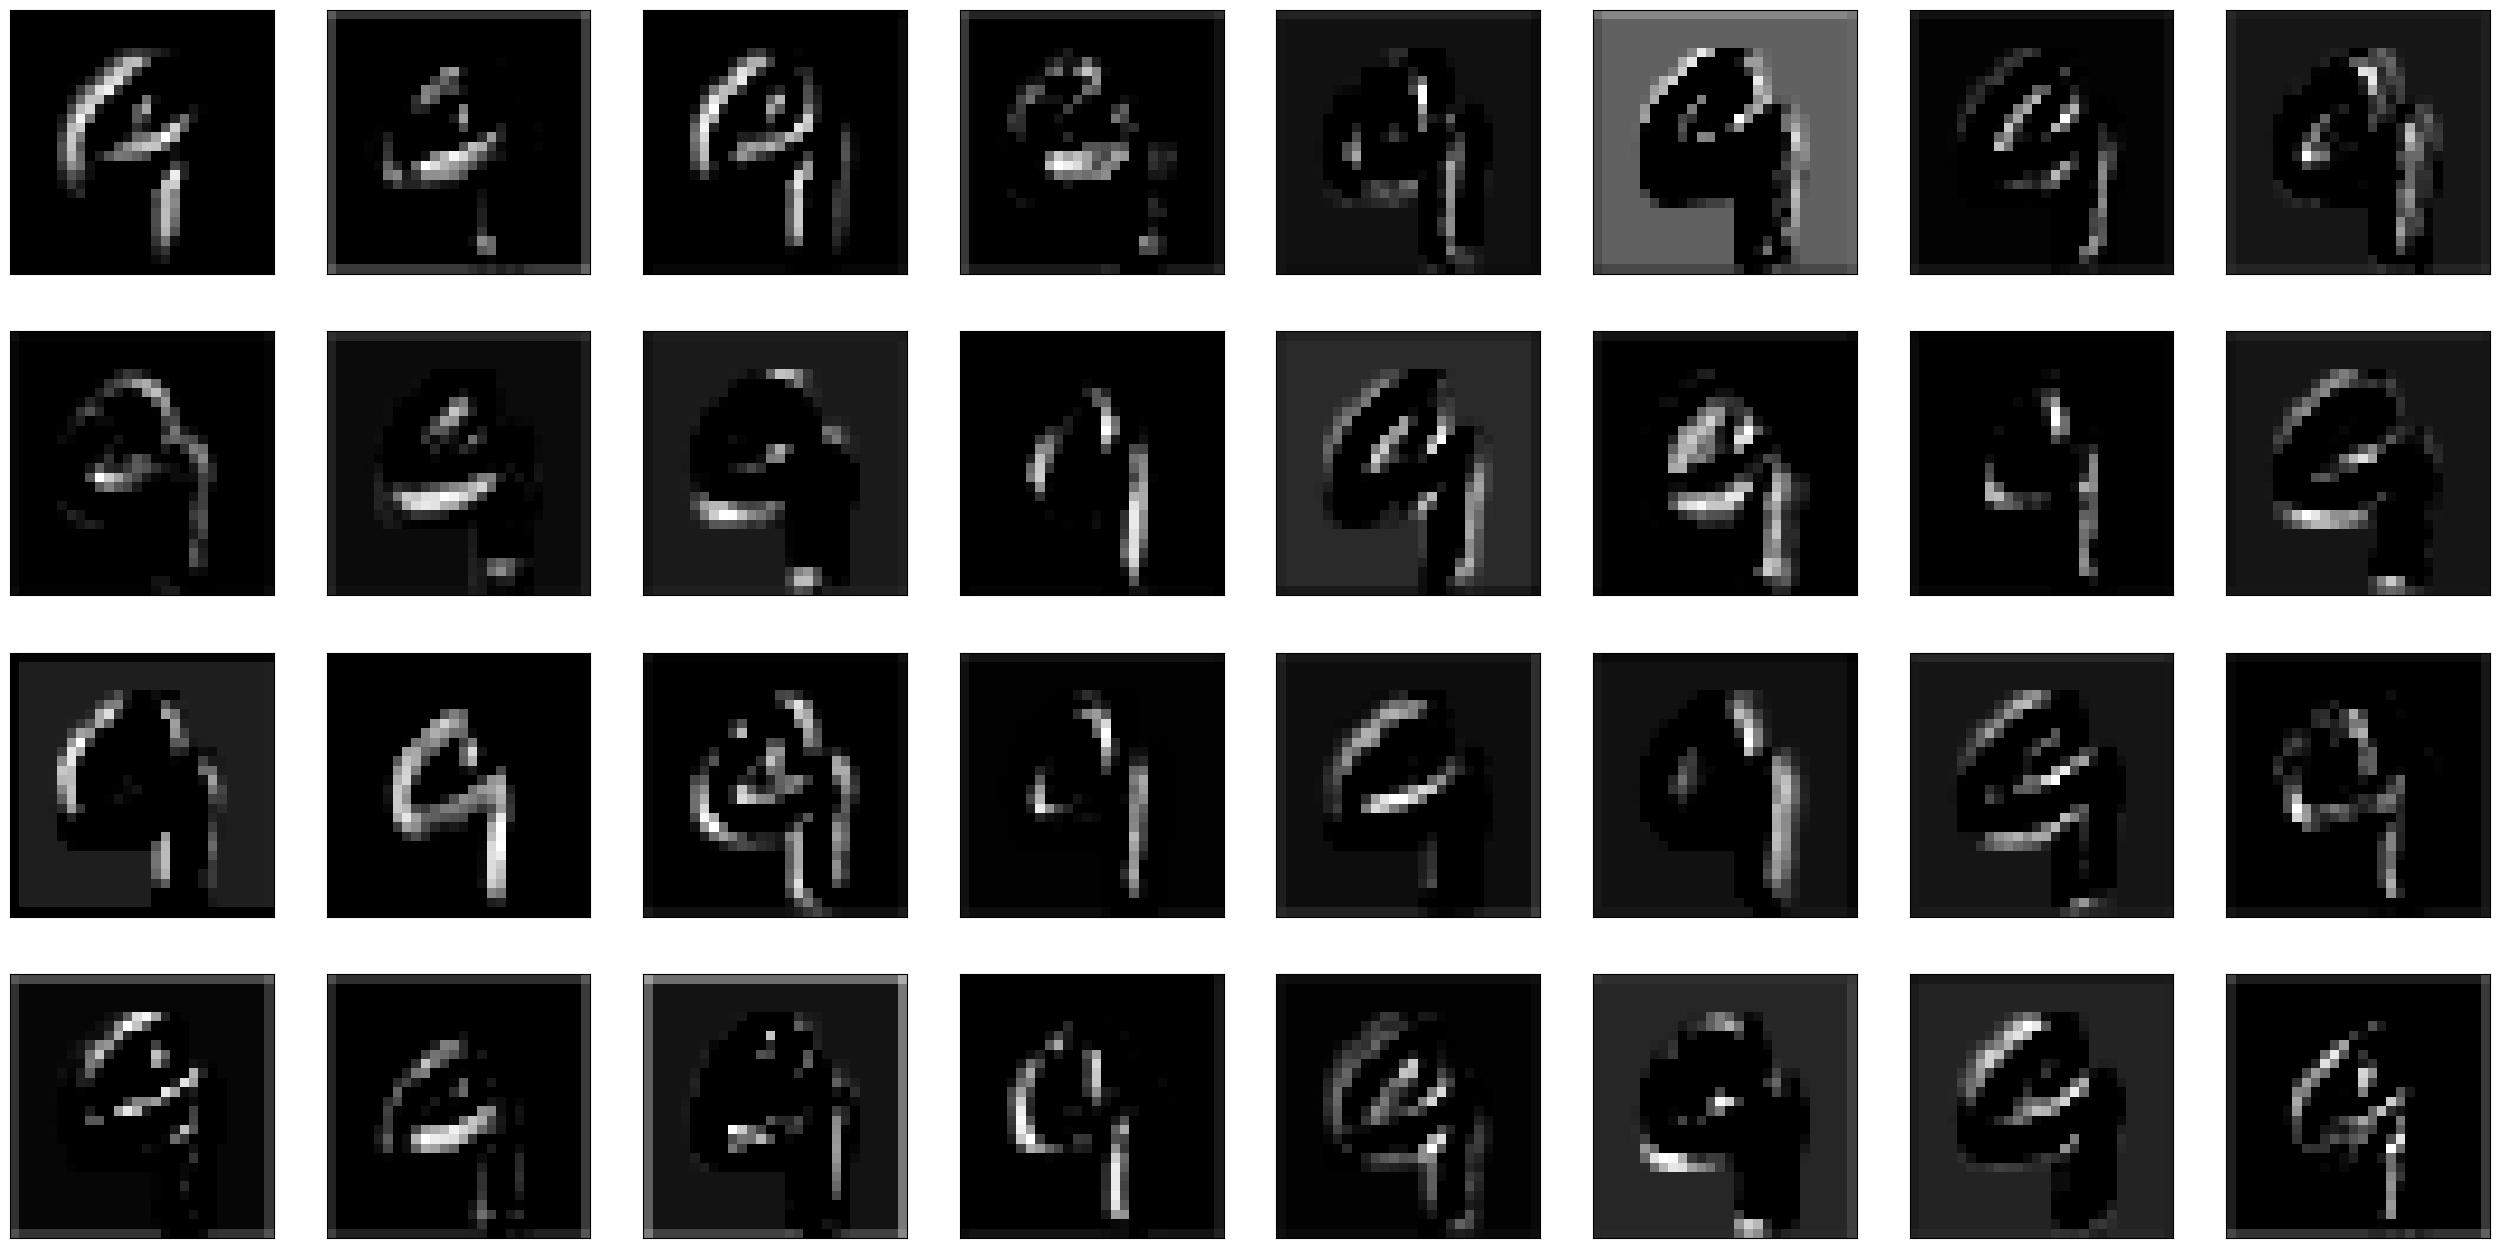

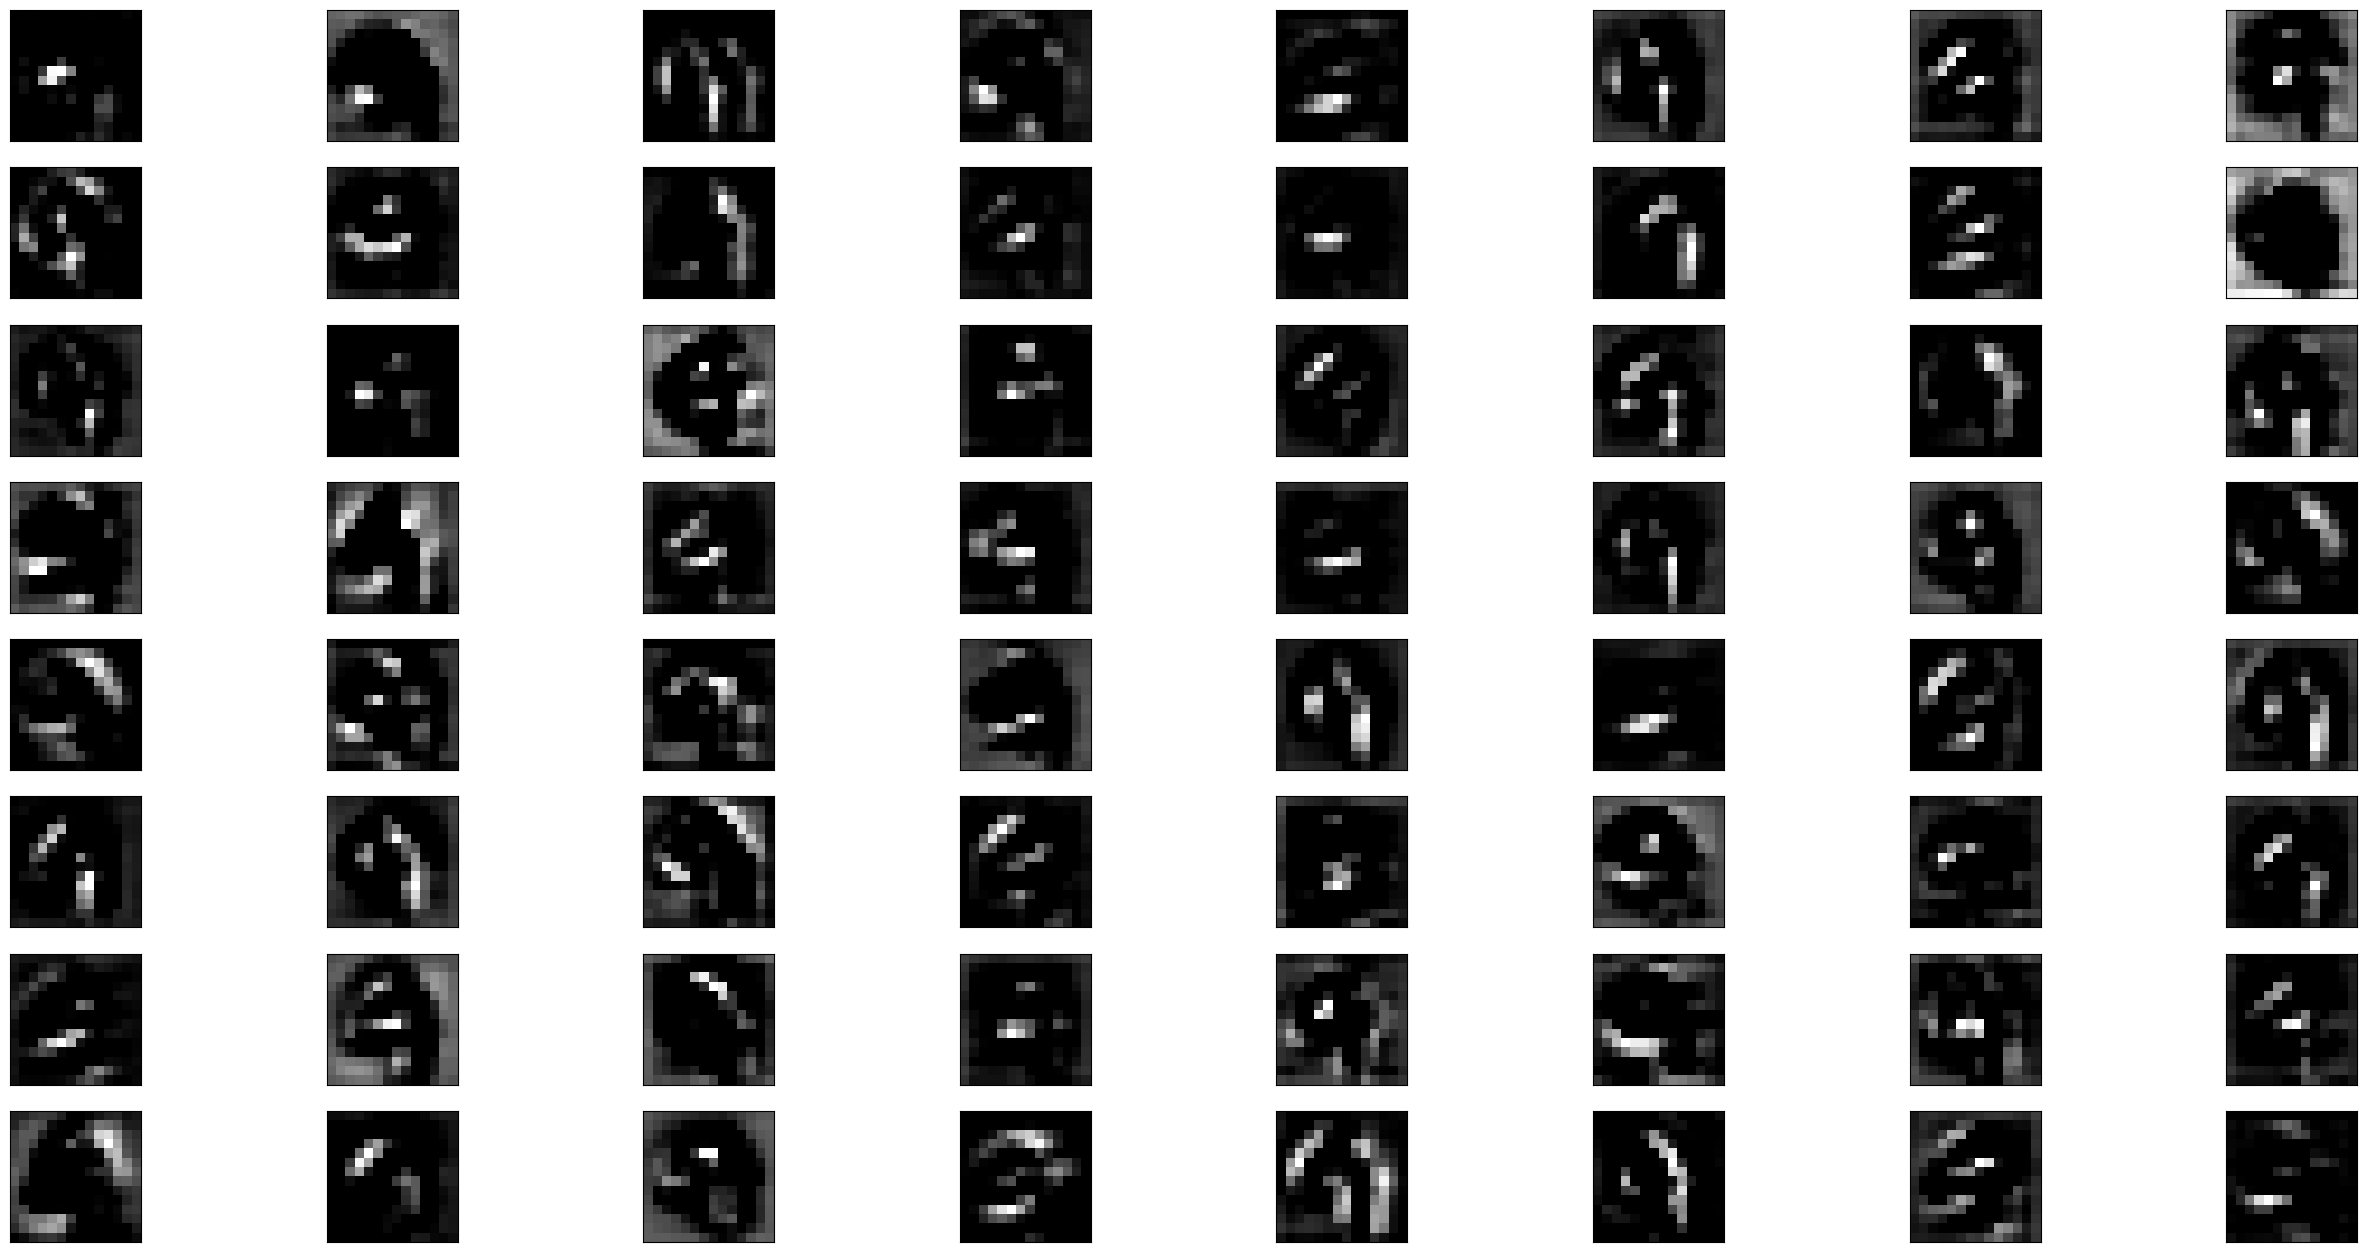

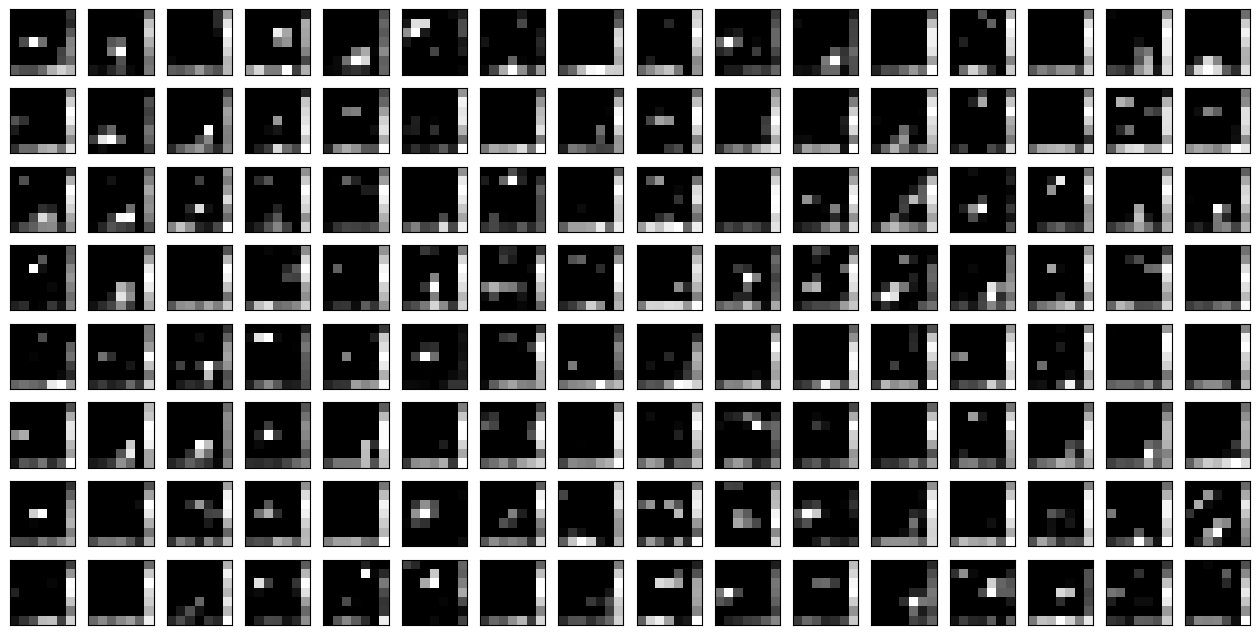

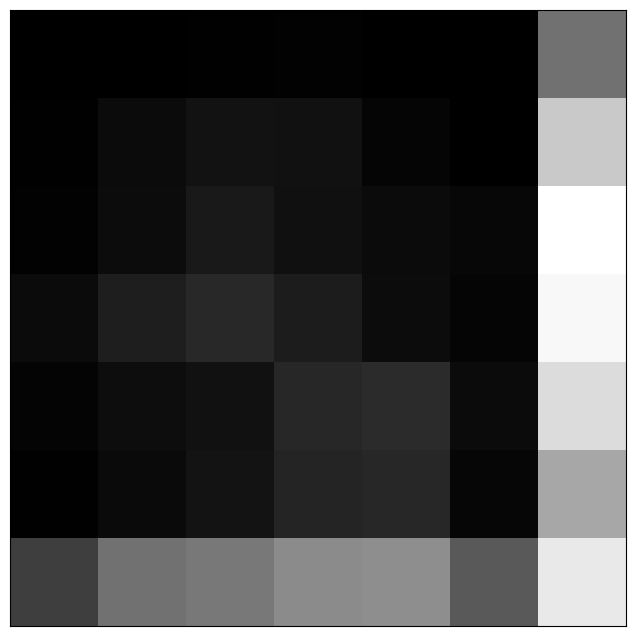

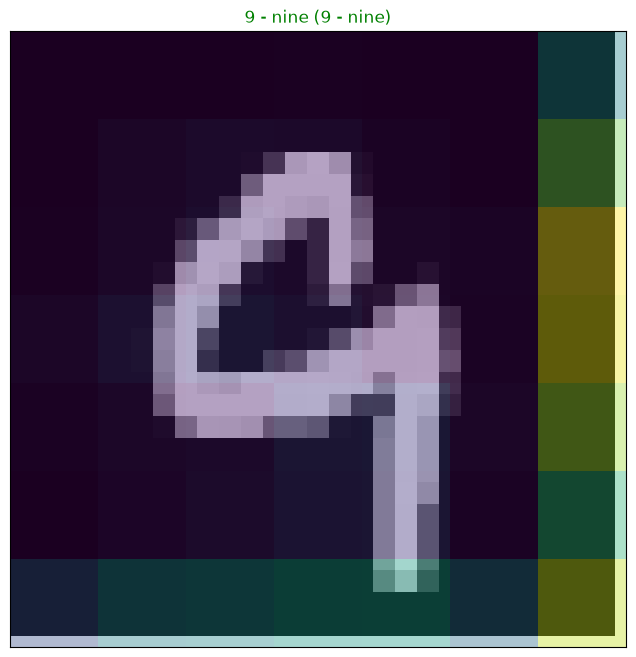

In [ ]:
lm.eval()
with torch.no_grad():
    xb, yb = next(iter(tedl))
    xb = xb.to(D)
    yb = yb.to(D)
    yhat = lm(xb)
    pred = yhat.argmax(dim=1)
    # cnn 할 때 사용
    fm1 = lm.c1(xb)
    fm2 = lm.c2(lm.mp(fm1))
    fm3 = lm.c3(lm.mp(fm2))
    # cdeep할 때 사용
    # fm1 = lm.cb1(xb)
    # fm2 = lm.cb2(lm.mp(fm1))
    # fm3 = lm.cb3(lm.mp(fm2))
xb = xb.cpu()
fm1 = fm1.cpu()
fm2 = fm2.cpu()
fm3 = fm3.cpu()
plt.figure(figsize=(8, 8))
plt.xticks([])
plt.yticks([])
plt.imshow(xb[0, 0], cmap="gray")
print(fm1.shape)
plt.figure(figsize=(32, 16))
for i in range(fm1.shape[1]):
    plt.subplot(4, 8, i + 1, xticks=[], yticks=[])
    plt.imshow(fm1[0, i], cmap="gray")
print(fm2.shape)
plt.figure(figsize=(32, 16))
for i in range(fm2.shape[1]):
    plt.subplot(8, 8, i + 1, xticks=[], yticks=[])
    plt.imshow(fm2[0, i], cmap="gray")
print(fm3.shape)
plt.figure(figsize=(16, 8))
for i in range(fm3.shape[1]):
    plt.subplot(8, 16, i + 1, xticks=[], yticks=[])
    plt.imshow(fm3[0, i], cmap="gray")
sm = fm3.sum(dim=1)
plt.figure(figsize=(8, 8))
plt.xticks([])
plt.yticks([])
plt.imshow(sm[0], cmap="gray")
plt.figure(figsize=(8, 8))
plt.xticks([])
plt.yticks([])
plt.imshow(xb[0, 0], cmap="gray")
plt.imshow(sm[0], extent=[0, 28, 28, 0], alpha=0.4, cmap="viridis")
pi = teds.classes[pred[0].item()]
ti = teds.classes[yb[0].item()]
plt.title(f"{pi} ({ti})", color="g" if pi == ti else "r")